# Long-term stress response
looking back at my proposal defense notes, Freddy and Sarah D. pointed out that a better comparison to pick out the long- and short-term response to stress would be CH vs. HC (instead of HH vs. HC) because these oysters both experienced one stressor but at different time points. 

(But also, couldn't you compare the up- and down-regulated genes of CC vs. HC and CC vs. CH? Because then you'd know the direction of expression, instead of trying to guess if it's up-regulated bc of the most recent exposure or because of long-term response? idk which makes more sense - I suppose I should do both)

## 0. load libraries

In [2]:
library(tidyverse)
library(RColorBrewer)
library(rtracklayer) # for reading GTF file
library(UpSetR)
library(clusterProfiler) # for ORA

## 1. read csvs
### DEGs

In [3]:
# get list of files
files <- list.files(
    path = '/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/DEGs/',
    pattern = '\\.csv$',
    full.names = TRUE
    )

head(files)

[1] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/DEGs//DEG_bb_cc.csv"
[2] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/DEGs//DEG_bc_bb.csv"
[3] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/DEGs//DEG_bc_cc.csv"
[4] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/DEGs//DEG_bc_hc.csv"
[5] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/DEGs//DEG_bc_wc.csv"
[6] "/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/DEGs//DEG_bh_bb.csv"

In [4]:
names(files) <- gsub('DEG_', '', tools::file_path_sans_ext(basename(files)))
df_list <- lapply(files, read.csv)
names(df_list)
length(df_list)

[1] "bb_cc"        "bc_bb"        "bc_cc"        "bc_hc"        "bc_wc"       
 [6] "bh_bb"        "bh_bc"        "bh_bw"        "bh_ch"        "bh_hh"       
[11] "bw_bb"        "bw_bc"        "bw_cw"        "bw_ww"        "cb_bb"       
[16] "cb_bc"        "cb_cc"        "cb_ch"        "cb_cw"        "ch_cc"       
[21] "ch_hc"        "cw_cc"        "cw_ch"        "cw_wc"        "hb_bb"       
[26] "hb_bh"        "hb_cb"        "hb_hc"        "hb_hh"        "hb_hw"       
[31] "hc_cc"        "hc_hh"        "hh_cc"        "hh_ch"        "hw_bw"       
[36] "hw_cw"        "hw_hc"        "hw_hh"        "hw_ww"        "vst_filtered"
[41] "wb_bb"        "wb_bw"        "wb_cb"        "wb_hb"        "wb_wc"       
[46] "wb_wh"        "wb_ww"        "wc_cc"        "wc_hc"        "wc_ww"       
[51] "wh_bh"        "wh_ch"        "wh_hh"        "wh_hw"        "wh_wc"       
[56] "wh_ww"        "ww_cc"        "ww_cw"

[1] 58

In [5]:
# only grab the dfs i'm interested in
deg.list <- df_list[c('ch_hc', 'cw_wc', 'cb_bc', 'ch_cc', 'hc_cc', 'cw_cc', 'wc_cc', 'bc_cc', 'cb_cc')]
names(deg.list)

[1] "ch_hc" "cw_wc" "cb_bc" "ch_cc" "hc_cc" "cw_cc" "wc_cc" "bc_cc" "cb_cc"

In [6]:
# combine into one df
deg.df <- bind_rows(deg.list, .id = "comparison")

# rename gene column 
colnames(deg.df)[2] <- 'gene'

head(deg.df)

,comparison,gene,baseMean,log2FoldChange,lfcSE,pvalue,padj,pair,DEG_group
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
1,ch_hc,LOC144622046,14.97323,-20.863903,3.308651,1.319192e-10,1.370957e-07,HC vs. CH,HC
2,ch_hc,LOC144622060,65.28037,19.692960,3.120874,1.386469e-10,1.385456e-07,HC vs. CH,CH
3,ch_hc,LOC111103137,103.49992,2.980083,2.059201,3.282576e-05,1.349055e-02,HC vs. CH,CH
4,ch_hc,LOC144619407,11.94387,18.554174,3.961737,3.147059e-07,1.739654e-04,HC vs. CH,CH
5,ch_hc,LOC144623974,82.70086,-15.328927,8.816992,2.335978e-05,1.011517e-02,HC vs. CH,HC
6,ch_hc,LOC111104604,153.21759,-23.877694,4.477703,2.636896e-08,1.903033e-05,HC vs. CH,HC


### gene annotations

In [7]:
genes <- as.data.frame(import('/project/pi_sarah_gignouxwolfsohn_uml_edu/Reference_genomes/Cvirginica_genome/new_cvir_genome/GCF_053477285.1_ASM5347728v1_genomic.gff')) %>%
dplyr::select(gene, description) %>% 
na.omit()

head(genes)

,gene,description
,<chr>,<chr>
2,LOC144621260,protein O-mannosyl-transferase TMTC2-like
28,LOC144621269,uncharacterized LOC144621269
63,LOC111120925,mitochondrial amidoxime-reducing component 1-like
79,Trnae-cuc,transfer RNA glutamic acid (anticodon CUC)
82,Trnae-cuc,transfer RNA glutamic acid (anticodon CUC)
85,Trnae-cuc,transfer RNA glutamic acid (anticodon CUC)


### enrichment inputs
need 2 dfs:
1. term2gene: 2 cols for GO term and gene
2. term2name: 2 cols for GO term and GO name

In [8]:
# for gene enrichment
GO <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/Reference_genomes/Cvirginica_genome/annotations/gene2GO_name.csv')

# make GO dfs
term2gene <- GO %>% select(term, gene)
term2name <- GO %>% select(term, name)

head(term2gene)
head(term2name)

,term,gene
,<chr>,<chr>
1,GO:0000002,LOC111135903
2,GO:0000009,LOC111133213
3,GO:0000012,LOC111111498
4,GO:0000012,LOC144626581
5,GO:0000014,LOC111111711
6,GO:0000015,LOC111132341


,term,name
,<chr>,<chr>
1,GO:0000002,mitochondrial genome maintenance
2,GO:0000009,"alpha-1,6-mannosyltransferase activity"
3,GO:0000012,single strand break repair
4,GO:0000012,single strand break repair
5,GO:0000014,single-stranded DNA endodeoxyribonuclease activity
6,GO:0000015,phosphopyruvate hydratase complex


## 2. barplot - # of DEGs

pulling out only the comparisons that get at timing (not comparing against CC)

In [34]:
timing.df <- deg.df %>% 
filter(!grepl('cc', comparison)) %>%
mutate(stress_timing = case_when(
    # if C is first, the stress was experienced later/second
    substr(DEG_group, 1, 1) == "C" ~ "second",
    # if C is second, the stress was experienced early/first
    substr(DEG_group, 2, 2) == "C" ~ "first"
  ))

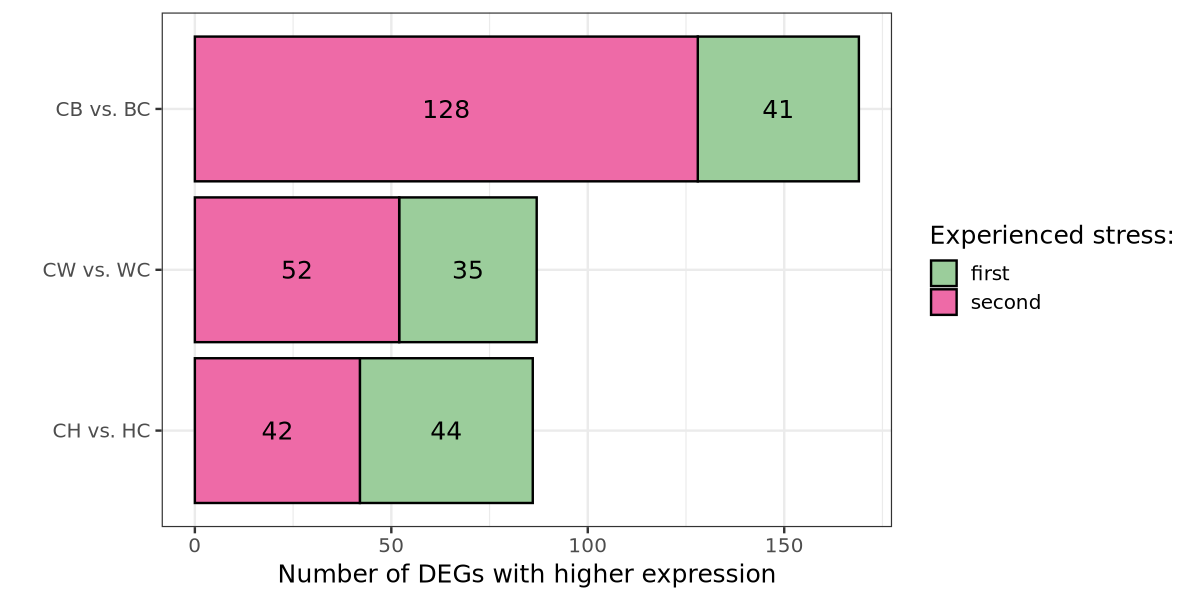

In [46]:
options(repr.plot.height = 5, repr.plot.width = 10)

ggplot(timing.df, aes(x = fct_rev(fct_infreq(comparison)), fill = stress_timing)) +
geom_bar(col = 'black') +
  geom_text(stat = "count",
            aes(label = after_stat(count), group = stress_timing),
            position = position_stack(vjust = 0.5)) +
theme_bw(base_size = 15) +
coord_flip() +
scale_x_discrete(labels = c(
    ch_hc = "CH vs. HC",
    cw_wc = "CW vs. WC",
    cb_bc = "CB vs. BC"
  )) +
scale_fill_manual(values = c('darkseagreen3', 'hotpink2')) +
labs(x = '',
    y = 'Number of DEGs with higher expression',
     fill = 'Experienced stress:')

so we mainly see higher expression of DEGs in the oyster that experienced the stress later in life (so higher expression in CB/lower expression in BC) - this isn't true for CH vs. HC (it's about even)

## 3. upset plot

In [56]:
# one vector of genes per comparison
gene.list <- split(deg.df$gene, deg.df$comparison)

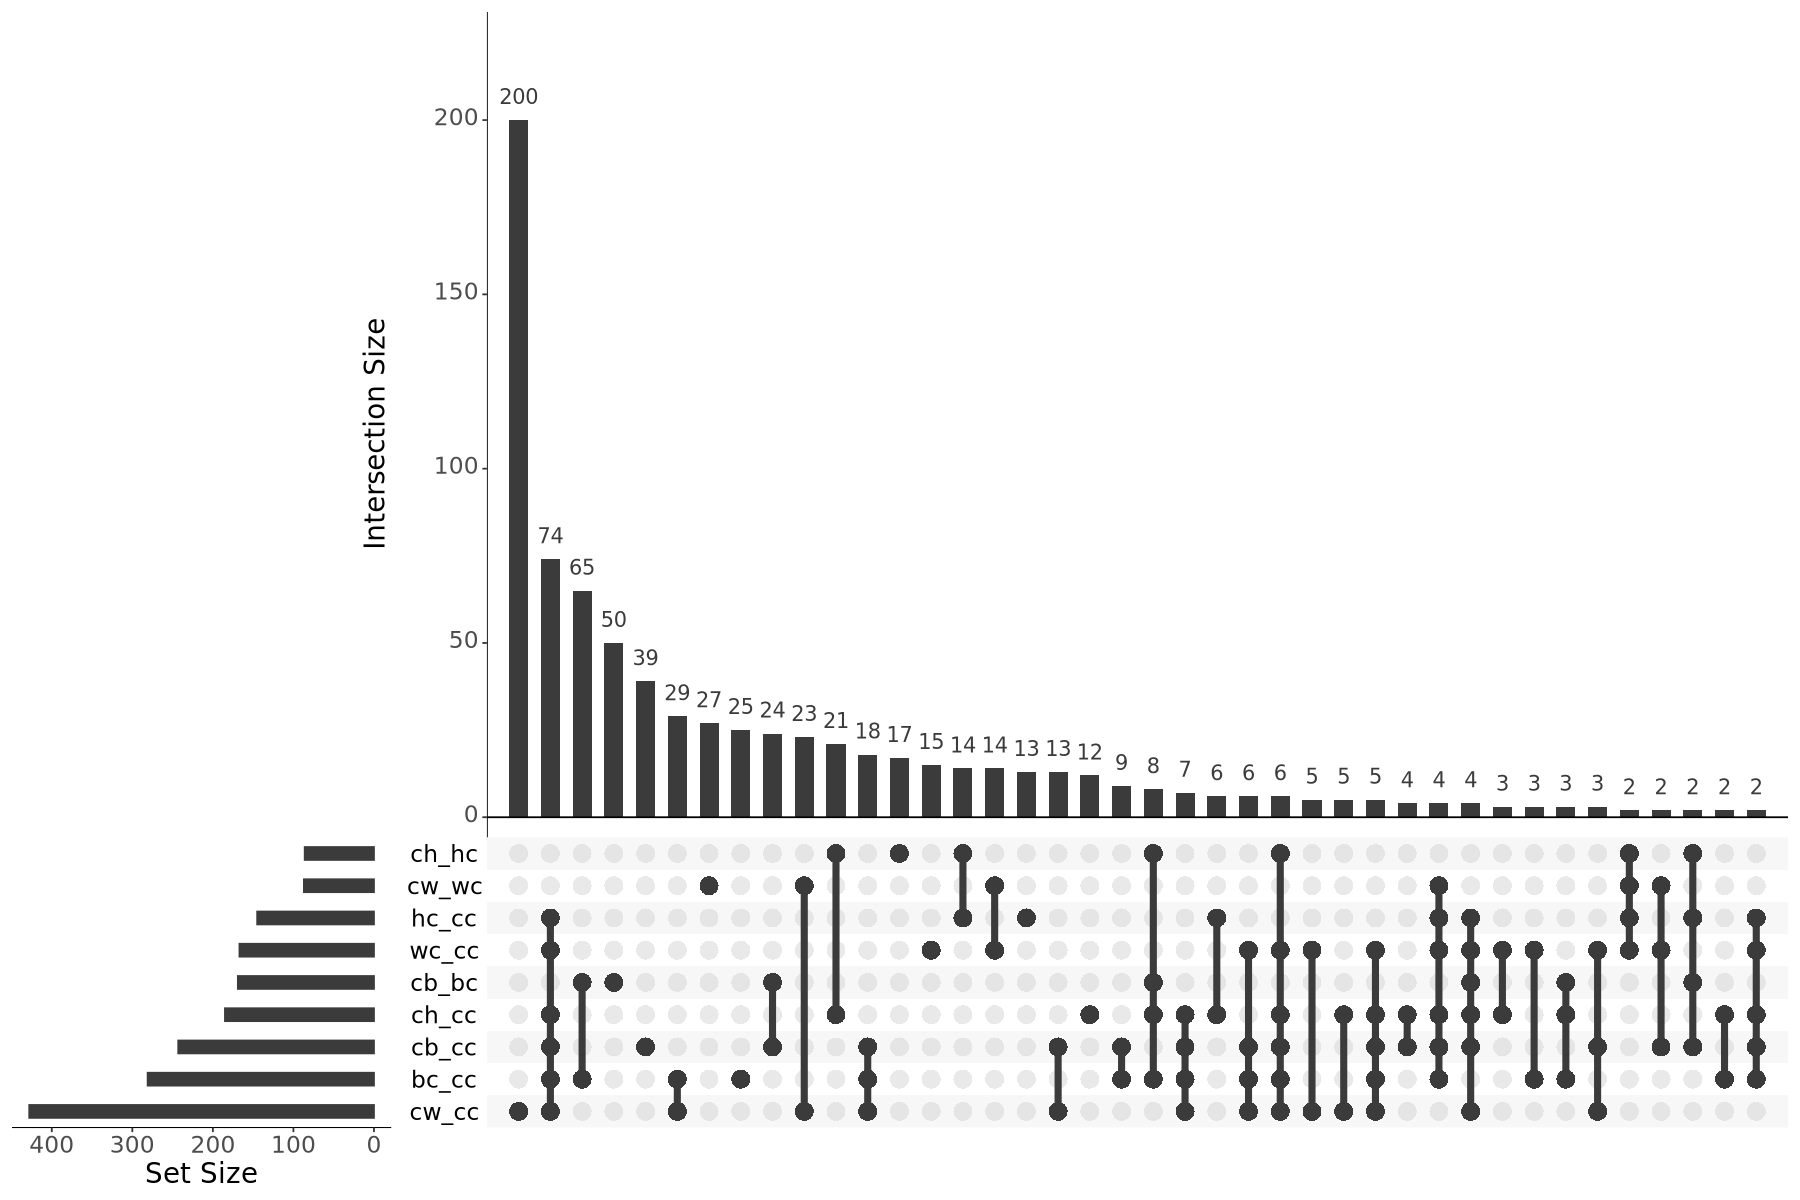

In [61]:
options(repr.plot.height = 10, repr.plot.width = 15)

upset(fromList(gene.list), 
      keep.order=TRUE,
      nsets = length(gene.list),
      point.size = 5, 
      line.size = 2,
      order.by = "freq",
         text.scale = c(2, 2, 2, 2, 2, 2))


doesn't look like there's any shared DEGs among CH vs. HC, CW vs. WC, and CB vs. BC - so no shared long-term stress-response genes among different environmental treatments

The most shared DEGs (74) are shared between all comparisons with CC, regardless of when the stress was experienced (which is what I've seen before; all of the stressed oysters only experienced stress at one timepoint) - this suggests a shared/general response to stress (but again, I've already looked at that in [this code](https://github.com/jgmcdonough/CE24_RNA-seq/blob/main/analysis/diff_expression/phase2_v_phase2/upset_p2.v.p2.ipynb))

## 4. annotate DEGs

#### CH vs. HC

In [118]:
hyp.genes <- deg.list$ch_hc$X
hyp.annot <- genes[genes$gene %in% hyp.genes,]

paste('Number of uncharacterized DEGs:', dim(hyp.annot %>% filter(grepl('uncharacterized', description)))[1])

hyp.annot %>% filter(!grepl('uncharacterized', description))

[1] "Number of uncharacterized DEGs: 69"

gene,description
<chr>,<chr>
LOC144619407,ganglioside GM2 activator-like
LOC111122505,cadherin EGF LAG seven-pass G-type receptor 2-like
LOC111124856,fibrinogen C domain-containing protein 1-like
LOC111116003,interferon-induced protein 44-like
LOC111111959,snaclec 4-like
LOC111113712,collectin-12-like
LOC144623338,perlucin-like protein
LOC144624111,perlucin-like protein
LOC144625715,E3 ubiquitin-protein ligase RNF213-like


### CB vs. BC

In [119]:
both.genes <- deg.list$cb_bc$X
both.annot <- genes[genes$gene %in% both.genes,]

paste('Number of uncharacterized DEGs:', dim(both.annot %>% filter(grepl('uncharacterized', description)))[1])

both.annot %>% filter(!grepl('uncharacterized', description))

[1] "Number of uncharacterized DEGs: 129"

gene,description
<chr>,<chr>
LOC144619407,ganglioside GM2 activator-like
LOC144619485,ficolin-1-like
LOC111101181,perlucin-like protein
LOC144625661,"defensin, isoforms B and C-like"
LOC111125091,von Willebrand factor D and EGF domain-containing protein-like
LOC144622538,cell adhesion molecule DSCAML1-like
LOC111127517,contactin-1-like
LOC111124622,sodium- and chloride-dependent glycine transporter 1-like
LOC111123314,cholesterol 7-desaturase nvd-like


### CW vs. WC

In [120]:
warm.genes <- deg.list$cw_wc$X
warm.annot <- genes[genes$gene %in% warm.genes,]

paste('Number of uncharacterized DEGs:', dim(warm.annot %>% filter(grepl('uncharacterized', description)))[1])

warm.annot %>% filter(!grepl('uncharacterized', description))

[1] "Number of uncharacterized DEGs: 73"

gene,description
<chr>,<chr>
LOC111102975,"glutathione S-transferase 3, mitochondrial-like"
LOC144619407,ganglioside GM2 activator-like
LOC144620744,N-lysine methyltransferase KMT5A-like
LOC111127528,histamine H3 receptor-like
LOC111124856,fibrinogen C domain-containing protein 1-like
LOC144624111,perlucin-like protein
LOC144624363,kappaPI-actitoxin-Ael3a-like
LOC111132942,membrane metallo-endopeptidase-like 1
LOC144627833,glutamate receptor-interacting protein 2-like


## 5. ORA enrichment

#### CH vs. HC

In [67]:
hyp_universe <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/ch_hc.csv')
head(hyp_universe)

,X,baseMean,log2FoldChange,lfcSE,pvalue,padj
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,LOC144621260,1949.4353,-0.0038243839,0.05522008,0.77570773,0.9901066
2,LOC144621269,2097.0613,0.0015192658,0.07828301,0.68833177,0.9888299
3,LOC111120925,132.0849,-0.0109943506,0.17180926,0.11656668,0.7829513
4,LOC144621283,866.8099,-0.0118882822,0.05552958,0.37674168,0.9402360
5,LOC144621276,12195.3765,-0.0377597602,0.05651590,0.03470123,0.5966728
6,LOC111115920,171.8729,0.0001779126,0.05714262,0.98101320,1.0000000


In [82]:
hyp_ora <- enricher(
     gene = deg.list$ch_hc$X,
     TERM2GENE = term2gene,
     TERM2NAME = term2name,
     pvalueCutoff = 0.05,
     pAdjustMethod = "BH",
     universe = hyp_universe$X)

hyp.df <- as.data.frame(hyp_ora) %>% mutate(comp = 'CH vs. HC')
hyp.df

,ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count,comp
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<chr>
GO:0009898,GO:0009898,cytoplasmic side of plasma membrane,2/27,11/10514,0.0003443549,0.009641938,0.008337014,LOC144619407/LOC111128341,2,CH vs. HC
GO:0005319,GO:0005319,lipid transporter activity,2/27,23/10514,0.0015542114,0.021502194,0.018592122,LOC144619407/LOC111128341,2,CH vs. HC
GO:0006869,GO:0006869,lipid transport,2/27,28/10514,0.0023038065,0.021502194,0.018592122,LOC144619407/LOC111128341,2,CH vs. HC


#### CW vs. WC

In [73]:
warm_universe <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/cw_wc.csv')
head(warm_universe)

,X,baseMean,log2FoldChange,lfcSE,pvalue,padj
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,LOC144621260,1949.4353,0.051072672,0.1426527,0.5690362,0.8713366
2,LOC144621269,2097.0613,0.032654141,0.2173765,0.2047771,0.6386391
3,LOC111120925,132.0849,-0.013859203,0.1980227,0.5409203,0.8577619
4,LOC144621283,866.8099,-0.006866949,0.1428074,0.9389260,0.9871909
5,LOC144621276,12195.3765,-0.090136750,0.1228125,0.3230504,0.7378920
6,LOC111115920,171.8729,-0.052274477,0.1695785,0.4265558,0.8013003


In [78]:
warm_ora <- enricher(
     gene = deg.list$cw_wc$X,
     TERM2GENE = term2gene,
     TERM2NAME = term2name,
     pvalueCutoff = 0.05,
     pAdjustMethod = "BH",
     universe = warm_universe$X)

warm.df <- as.data.frame(warm_ora)
warm.df

ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<int>


no enriched terms! interesting

#### CB vs. BC

In [75]:
both_universe <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/analysis/diff_expression/phase2_v_phase2/deseq_res/prefilter_deseq/cb_bc.csv')
head(both_universe)

,X,baseMean,log2FoldChange,lfcSE,pvalue,padj
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,LOC144621260,1949.4353,0.048874784,0.1275388,0.448011282,0.8746440
2,LOC144621269,2097.0613,-0.012537072,0.1897295,0.563085869,0.9179377
3,LOC111120925,132.0849,0.233329703,0.9539007,0.005163739,0.1669397
4,LOC144621283,866.8099,-0.001664763,0.1220830,0.978749639,0.9965885
5,LOC144621276,12195.3765,0.058377877,0.1108151,0.379620842,0.8417124
6,LOC111115920,171.8729,0.012830221,0.1521291,0.798277452,0.9670909


In [80]:
both_ora <- enricher(
     gene = deg.list$cb_bc$X,
     TERM2GENE = term2gene,
     TERM2NAME = term2name,
     pvalueCutoff = 0.05,
     pAdjustMethod = "BH",
     universe = both_universe$X)

both.df <- as.data.frame(both_ora) %>% mutate(comp = 'CB vs. BC')
both.df

,ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count,comp
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<chr>
GO:0006869,GO:0006869,lipid transport,4/53,28/10514,1.077224e-05,0.0005062951,0.0003968719,LOC144619407/LOC144622387/LOC144622389/LOC111138228,4,CB vs. BC
GO:0008234,GO:0008234,cysteine-type peptidase activity,3/53,20/10514,1.297841e-04,0.0030499268,0.0023907601,LOC111113029/LOC111113025/LOC111113026,3,CB vs. BC
GO:0006508,GO:0006508,proteolysis,5/53,172/10514,1.681836e-03,0.0263487564,0.0206541204,LOC111113029/LOC111113025/LOC111113026/LOC111137950/LOC111128165,5,CB vs. BC


### GO plots

In [96]:
combo.df <- rbind(hyp.df, both.df)
combo.df <- combo.df %>%
  arrange(comp, Description) %>%
  mutate(Description = factor(Description, levels = unique(Description)))

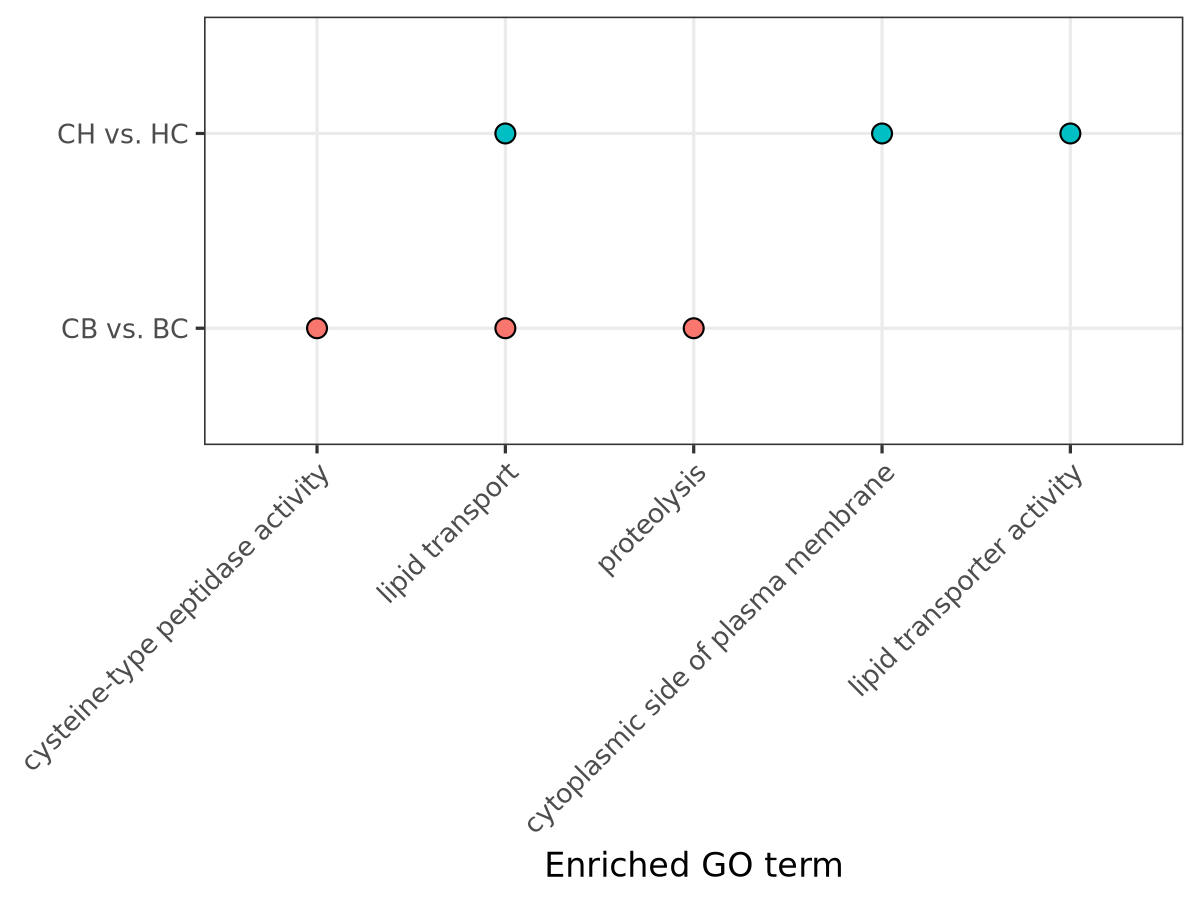

In [110]:
options(repr.plot.height = 7.5, repr.plot.width = 10)

ggplot(combo.df, aes(x = Description, y = comp, fill = comp)) +
geom_point(size = 5, shape = 21, col = 'black') +
theme_bw(base_size = 20) +
guides(fill = 'none') +
scale_color_brewer(palette = 'Paired') +
theme(axis.text.x = element_text(angle = 45, hjust = 1, vjust = 1)) +
labs(x = 'Enriched GO term',
     y = '')

both comparisons have DEGs enriched for lipid transport - moving lipids between different intracellular membranes (potentially interesting [paper](https://files.sciengine.com/pdfs/2095-8137/4CC1D5BA7E2A4B2EB3E7AD71B434DCF4.pdf) related to lipids in oysters adapted to warm temperature)

## 6. pull long-term stress genes

I had a thought - with looking at CH vs. HC, the DEGs are due to the timing of experienced stress - so how do we know that HC didn't go back towards control conditions and so the difference is really due to CH (most recent exposure to hypoxia?)

I think I could get at this by looking at CC vs. HC - the difference here truly would be to an early exposure to hypoxia - and then could see if any of these overlap with DEGs seen in CH vs. HC

### hypoxia

In [14]:
# HC vs. CC DEGs
hc_cc.deg <- deg.list$hc_cc$X
paste('Number of DEGs in HC vs. CC:', length(hc_cc.deg))

# CH vs. HC DEGs
ch_hc.deg <- deg.list$ch_hc$X
paste('Number of DEGs in CH vs. HC:', length(ch_hc.deg))

# pull long-term hypoxic genes
hyp.longTerm <- ch_hc.deg[ch_hc.deg %in% hc_cc.deg]
paste('Number of DEGs shared between CC vs. HC and CH vs. HC:', length(hyp.longTerm))
hyp.longTerm

[1] "Number of DEGs in HC vs. CC: 145"

[1] "Number of DEGs in CH vs. HC: 86"

[1] "Number of DEGs shared between CC vs. HC and CH vs. HC: 27"

[1] "LOC144622046" "LOC111101301" "LOC144620237" "LOC144620359" "LOC144627283"
 [6] "LOC144622284" "LOC111122505" "LOC111099940" "LOC144622228" "LOC111123678"
[11] "LOC111124856" "LOC144623744" "LOC111116003" "LOC144623171" "LOC144624349"
[16] "LOC144625985" "LOC144626817" "LOC144626342" "LOC144617712" "LOC144618101"
[21] "LOC111110291" "LOC144618924" "LOC111135568" "LOC111118928" "LOC144620607"
[26] "LOC111121938" "LOC111122207"

it's interesting that there's more DEGs in HC vs. CC than CH vs. HC - this suggests that there's shared responses to hypoxic stress, since there are less DEGs in CH vs. HC (so they're more similar to each other than HC vs. CC)

In [37]:
hyp.longAnnot <- genes[genes$gene %in% hyp.longTerm,]

# uncharacterized DEGs
paste('Number of uncharacterized long-term DEGs:', dim(hyp.longAnnot %>% filter(grepl('uncharacterized', description)))[1])

# characterized DEGs
hyp.longAnnot <- hyp.longAnnot %>% filter(!grepl('characterized', description))
hyp.longAnnot

[1] "Number of uncharacterized long-term DEGs: 23"

gene,description
<chr>,<chr>
LOC111122505,cadherin EGF LAG seven-pass G-type receptor 2-like
LOC111124856,fibrinogen C domain-containing protein 1-like
LOC111116003,interferon-induced protein 44-like
LOC111110291,transient receptor potential cation channel subfamily M member-like 2


- [LOC111122505](https://www.ncbi.nlm.nih.gov/gene/?term=LOC111122505)
    - GO terms for calcium ion binding and homophilic cell-cell adhesion
- [LOC111124856](https://www.ncbi.nlm.nih.gov/gene/?term=LOC111124856)
    - no GO terms on NCBI
- [LOC111116003](https://www.ncbi.nlm.nih.gov/gene/?term=LOC111116003)
    - GO terms for GTP binding
- [LOC111110291](https://www.ncbi.nlm.nih.gov/gene/?term=LOC111110291)
    - GO terms for ligand-gated calcium channel activity and calcium ion transmembrane transport
 
so seems like these genes are all involved in some sort of calcium ion transport/binding
- [Sillanpaa et al., 2016](https://www.sciencedirect.com/science/article/pii/S1874778716300149) - shell growth requires calcium uptake and transport

In [41]:
merge(hyp.longAnnot %>% filter(!grepl('characterized', description)), GO, by = 'gene') %>%
add_row(gene = hyp.longAnnot$gene, description = hyp.longAnnot$description) %>%
mutate(long_stress = 'Hypoxic') 


gene,description,term,name,long_stress
<chr>,<chr>,<chr>,<chr>,<chr>
LOC111116003,interferon-induced protein 44-like,GO:0005525,GTP binding,Hypoxic
LOC111122505,cadherin EGF LAG seven-pass G-type receptor 2-like,NA,NA,Hypoxic
LOC111124856,fibrinogen C domain-containing protein 1-like,NA,NA,Hypoxic
LOC111116003,interferon-induced protein 44-like,NA,NA,Hypoxic
LOC111110291,transient receptor potential cation channel subfamily M member-like 2,NA,NA,Hypoxic


hmm okay something is up with my GO annotation file because there's some GO terms missing (i searched LOC111110291 on NCBI and there's GO terms associated with this gene that aren't in my file)

In [49]:
manual_GO <- tribble(
  ~gene,          ~name,
  "LOC111122505", "calcium ion binding",
  "LOC111122505", "homophilic cell-cell adhesion",
  "LOC111124856", NA_character_,
  "LOC111116003", "GTP binding",
  "LOC111110291", "ligand-gated calcium channel activity",
  "LOC111110291", "calcium ion transmembrane transport"
)

hyp.main <- merge(hyp.longAnnot %>% filter(!grepl('characterized', description)),
                  GO, by = 'gene')

hyp.final <- hyp.longAnnot %>%
  select(gene, description) %>%
  inner_join(manual_GO, by = 'gene') %>%
  bind_rows(hyp.main) %>%
  distinct(gene, name, .keep_all = TRUE) %>%
  mutate(long_stress = 'Hypoxic') %>%
select(gene, description, term, name, long_stress)

hyp.final

gene,description,term,name,long_stress
<chr>,<chr>,<chr>,<chr>,<chr>
LOC111122505,cadherin EGF LAG seven-pass G-type receptor 2-like,NA,calcium ion binding,Hypoxic
LOC111122505,cadherin EGF LAG seven-pass G-type receptor 2-like,NA,homophilic cell-cell adhesion,Hypoxic
LOC111124856,fibrinogen C domain-containing protein 1-like,NA,NA,Hypoxic
LOC111116003,interferon-induced protein 44-like,NA,GTP binding,Hypoxic
LOC111110291,transient receptor potential cation channel subfamily M member-like 2,NA,ligand-gated calcium channel activity,Hypoxic
LOC111110291,transient receptor potential cation channel subfamily M member-like 2,NA,calcium ion transmembrane transport,Hypoxic


### warm

In [25]:
# WC vs. CC DEGs
wc_cc.deg <- deg.list$wc_cc$X
paste('Number of DEGs in WC vs. CC:', length(wc_cc.deg))

# CW vs. WC DEGs
cw_wc.deg <- deg.list$cw_wc$X
paste('Number of DEGs in CW vs. WC:', length(cw_wc.deg))

# pull long-term warm genes
warm.longTerm <- cw_wc.deg[cw_wc.deg %in% wc_cc.deg]
paste('Number of DEGs shared between CC vs. WC and CW vs. WC:', length(warm.longTerm))
warm.longTerm

[1] "Number of DEGs in WC vs. CC: 167"

[1] "Number of DEGs in CW vs. WC: 87"

[1] "Number of DEGs shared between CC vs. WC and CW vs. WC: 25"

[1] "LOC144619407" "LOC111101277" "LOC144627222" "LOC144620391" "LOC111127528"
 [6] "LOC111123050" "LOC144625993" "LOC144625712" "LOC144625551" "LOC111119236"
[11] "LOC111126481" "LOC144626783" "LOC111106792" "LOC111132635" "LOC144618101"
[16] "LOC111100644" "LOC144618687" "LOC144619614" "LOC111115253" "LOC111118928"
[21] "LOC111118775" "LOC111118378" "LOC111111250" "LOC111114643" "LOC144621318"

same as before, more DEGs between WC vs. CC than CW vs. WC - implies that experiencing warming at any time point makes oysters more transcriptionally similar

In [26]:
warm.longAnnot <- genes[genes$gene %in% warm.longTerm,]

# uncharacterized DEGs
paste('Number of uncharacterized long-term DEGs:', dim(warm.longAnnot %>% filter(grepl('uncharacterized', description)))[1])

# characterized DEGs
warm.longAnnot %>% filter(!grepl('characterized', description))

[1] "Number of uncharacterized long-term DEGs: 22"

gene,description
<chr>,<chr>
LOC144619407,ganglioside GM2 activator-like
LOC111127528,histamine H3 receptor-like
LOC144619614,scavenger receptor cysteine-rich domain-containing protein DMBT1-like


- [LOC144619407](https://www.ncbi.nlm.nih.gov/gene/?term=LOC144619407)
- [LOC111127528](https://www.ncbi.nlm.nih.gov/gene/?term=LOC111127528)
- [LOC144619614](https://www.ncbi.nlm.nih.gov/gene/?term=LOC144619614)
 


In [32]:
warm.go <- merge(warm.longAnnot %>% filter(!grepl('characterized', description)), GO, by = 'gene') %>%
mutate(long_stress = 'Warm')
warm.go

gene,description,term,name,long_stress
<chr>,<chr>,<chr>,<chr>,<chr>
LOC111127528,histamine H3 receptor-like,GO:0007187,"G protein-coupled receptor signaling pathway, coupled to cyclic nucleotide second messenger",Warm
LOC111127528,histamine H3 receptor-like,GO:0004993,G protein-coupled serotonin receptor activity,Warm
LOC111127528,histamine H3 receptor-like,GO:0007268,chemical synaptic transmission,Warm
LOC111127528,histamine H3 receptor-like,GO:0030425,dendrite,Warm
LOC111127528,histamine H3 receptor-like,GO:0045202,synapse,Warm
LOC111127528,histamine H3 receptor-like,GO:0016907,G protein-coupled acetylcholine receptor activity,Warm
LOC111127528,histamine H3 receptor-like,GO:0007197,adenylate cyclase-inhibiting G protein-coupled acetylcholine receptor signaling pathway,Warm
LOC111127528,histamine H3 receptor-like,GO:0005886,plasma membrane,Warm
LOC144619407,ganglioside GM2 activator-like,GO:0009898,cytoplasmic side of plasma membrane,Warm


### both

In [28]:
# BC vs. CC DEGs
bc_cc.deg <- deg.list$bc_cc$X
paste('Number of DEGs in BC vs. CC:', length(bc_cc.deg))

# CB vs. BC DEGs
cb_bc.deg <- deg.list$cb_bc$X
paste('Number of DEGs in CB vs. BC:', length(cb_bc.deg))

# pull long-term warm genes
both.longTerm <- cb_bc.deg[cb_bc.deg %in% bc_cc.deg]
paste('Number of DEGs shared between CC vs. BC and CB vs. BC:', length(both.longTerm))
both.longTerm

[1] "Number of DEGs in BC vs. CC: 281"

[1] "Number of DEGs in CB vs. BC: 169"

[1] "Number of DEGs shared between CC vs. BC and CB vs. BC: 79"

[1] "LOC144619349" "LOC111105307" "LOC111104604" "LOC111104521" "LOC144618975"
 [6] "LOC144622389" "LOC144619712" "LOC144619748" "LOC144623030" "LOC144619749"
[11] "LOC144623854" "LOC144624325" "LOC111101181" "LOC144620003" "LOC144625494"
[16] "LOC144625661" "LOC144620154" "LOC111099586" "LOC111099828" "LOC111124714"
[21] "LOC111127517" "LOC111125415" "LOC111125416" "LOC111125424" "LOC111126527"
[26] "LOC111125235" "LOC144623075" "LOC111113813" "LOC111113785" "LOC144623338"
[31] "LOC111106798" "LOC111113025" "LOC111113026" "LOC111116096" "LOC111111516"
[36] "LOC144623989" "LOC111126010" "LOC144624224" "LOC144623427" "LOC111117049"
[41] "LOC111116546" "LOC111117277" "LOC111116715" "LOC144625169" "LOC111106312"
[46] "LOC144625757" "LOC111113650" "LOC111119645" "LOC144626867" "LOC111132086"
[51] "LOC111138022" "LOC111108634" "LOC144618085" "LOC111106396" "LOC144618125"
[56] "LOC111106424" "LOC111106829" "LOC111107803" "LOC144627767" "LOC111133291"
[61] "LOC144617513" "LOC111134466" "LOC111134820" "LOC144619248" "LOC111136443"
[66] "LOC144619165" "LOC111100591" "LOC144618865" "LOC111131584" "LOC111128193"
[71] "LOC111129282" "LOC111131665" "LOC111119937" "LOC144620607" "LOC111115339"
[76] "LOC111111873" "LOC111115093" "LOC111110895" "LOC111118024"

same as before, more DEGs between BC vs. CC than CB vs. BC - implies that experiencing warming at any time point makes oysters more transcriptionally similar

In [29]:
both.longAnnot <- genes[genes$gene %in% both.longTerm,]

# uncharacterized DEGs
paste('Number of uncharacterized long-term DEGs:', dim(both.longAnnot %>% filter(grepl('uncharacterized', description)))[1])

# characterized DEGs
both.longAnnot %>% filter(!grepl('characterized', description))

[1] "Number of uncharacterized long-term DEGs: 68"

gene,description
<chr>,<chr>
LOC111101181,perlucin-like protein
LOC144625661,"defensin, isoforms B and C-like"
LOC111127517,contactin-1-like
LOC144623338,perlucin-like protein
LOC111113025,procathepsin L-like
LOC111113026,procathepsin L-like
LOC144623989,perlucin-like protein
LOC111126010,putative ATP-dependent DNA helicase RecS
LOC111119645,cysteine-rich motor neuron 1 protein-like


11 characterized DEGs out of the 68 shared - 3 of them are perlucin-like protein (having to do with the nacreous layer of the shell), 2 of them are procathespin L-like (critical for cellular function, an inactive precursor form of cathepsin L, involved in immune response, a cystein protease - see [paper on cathespin L in pearl oysters](https://www.sciencedirect.com/science/article/pii/S1050464810001518))

In [33]:
both.go <- merge(both.longAnnot %>% filter(!grepl('characterized', description)), GO, by = 'gene') %>%
mutate(long_stress = 'Both')
both.go

gene,description,term,name,long_stress
<chr>,<chr>,<chr>,<chr>,<chr>
LOC111113025,procathepsin L-like,GO:0006508,proteolysis,Both
LOC111113025,procathepsin L-like,GO:0008234,cysteine-type peptidase activity,Both
LOC111113026,procathepsin L-like,GO:0008234,cysteine-type peptidase activity,Both
LOC111113026,procathepsin L-like,GO:0006508,proteolysis,Both
LOC111127517,contactin-1-like,GO:0050839,cell adhesion molecule binding,Both
LOC111127517,contactin-1-like,GO:0005911,cell-cell junction,Both
LOC111127517,contactin-1-like,GO:0098609,cell-cell adhesion,Both
LOC111127517,contactin-1-like,GO:0005886,plasma membrane,Both
LOC144625661,"defensin, isoforms B and C-like",GO:0005615,extracellular space,Both


plotting this:

In [54]:
long_stress <- rbind(hyp.final, both.go, warm.go)
dim(long_stress)
head(long_stress)

[1] 32  5

,gene,description,term,name,long_stress
,<chr>,<chr>,<chr>,<chr>,<chr>
1,LOC111122505,cadherin EGF LAG seven-pass G-type receptor 2-like,NA,calcium ion binding,Hypoxic
2,LOC111122505,cadherin EGF LAG seven-pass G-type receptor 2-like,NA,homophilic cell-cell adhesion,Hypoxic
3,LOC111124856,fibrinogen C domain-containing protein 1-like,NA,NA,Hypoxic
4,LOC111116003,interferon-induced protein 44-like,NA,GTP binding,Hypoxic
5,LOC111110291,transient receptor potential cation channel subfamily M member-like 2,NA,ligand-gated calcium channel activity,Hypoxic
6,LOC111110291,transient receptor potential cation channel subfamily M member-like 2,NA,calcium ion transmembrane transport,Hypoxic


In [76]:
long_stress2 <- long_stress %>%
  arrange(long_stress, name) %>%
  mutate(name = factor(name, levels = unique(name))) %>%
filter(!is.na(name))

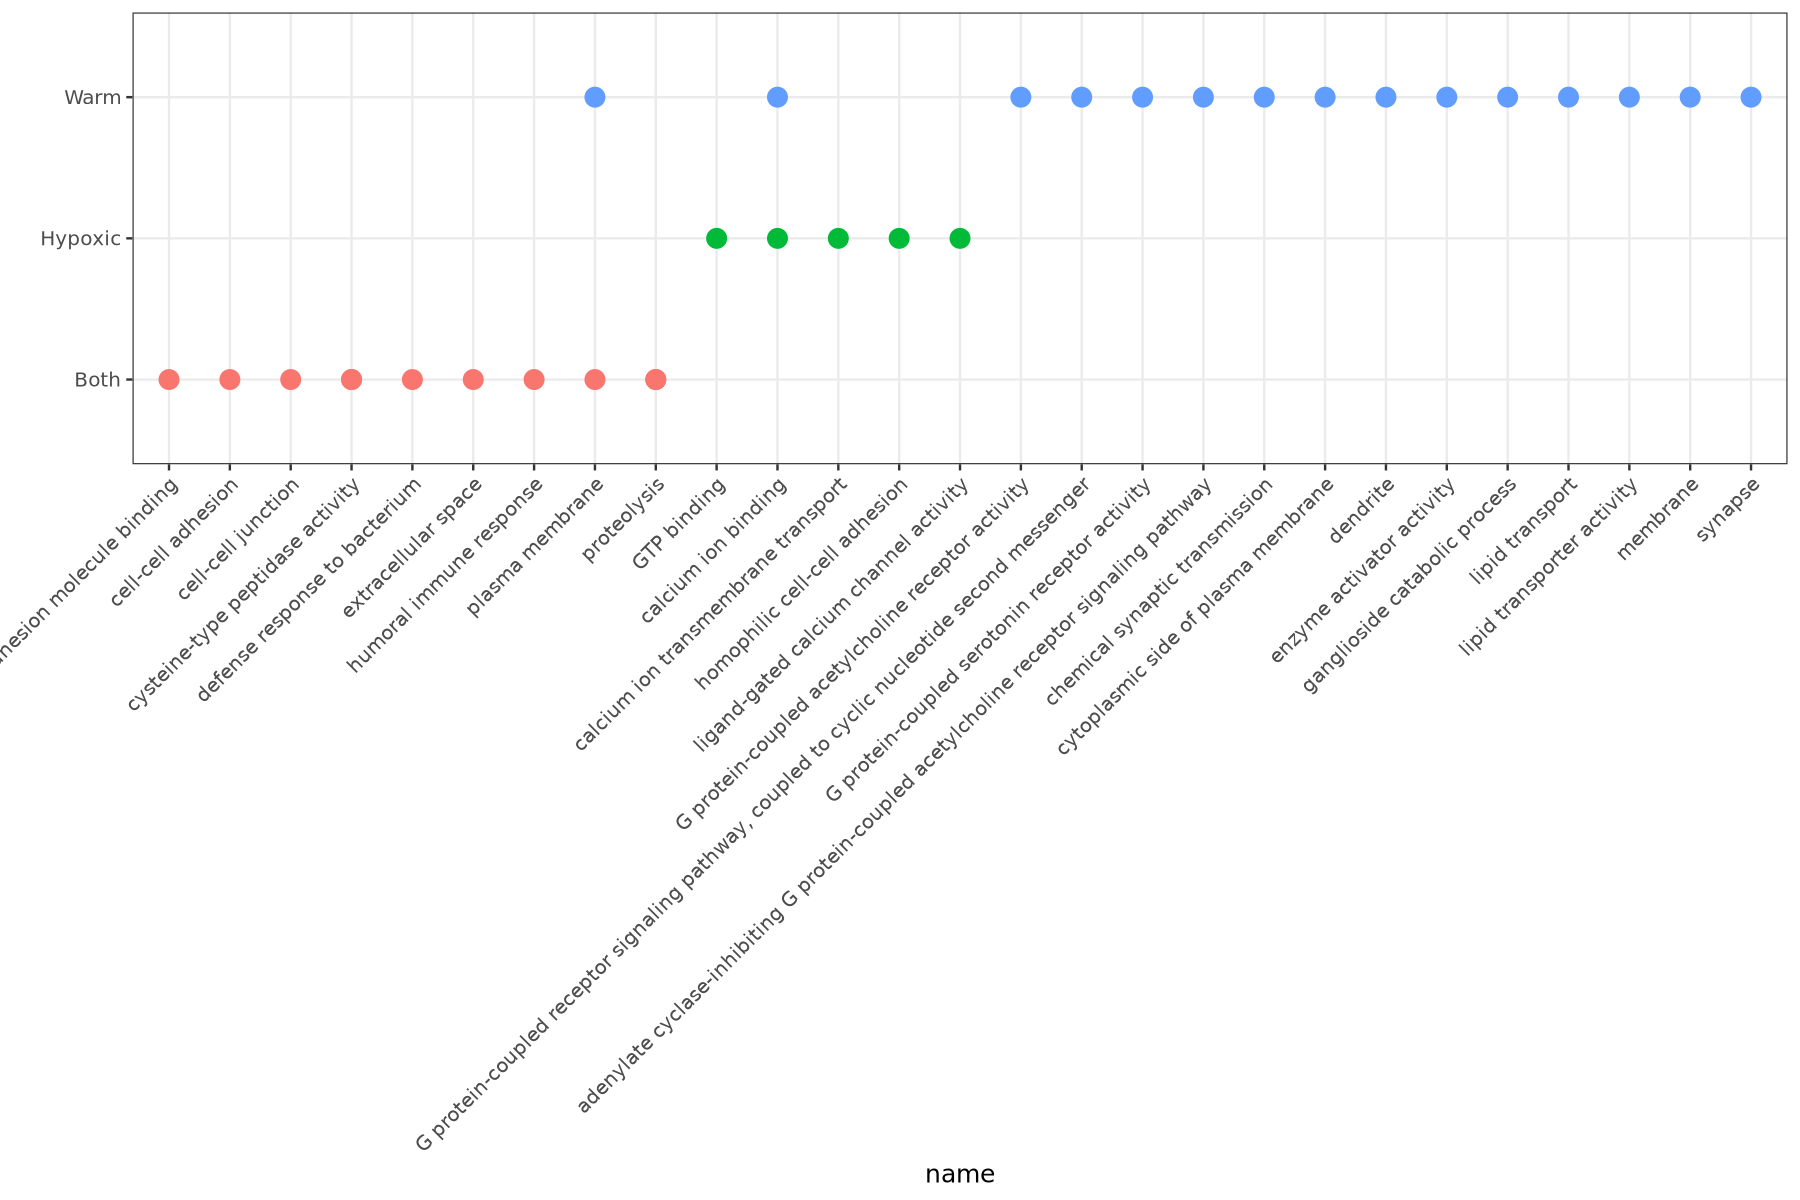

In [77]:
options(repr.plot.height = 10, repr.plot.width = 15)

ggplot(long_stress2, aes(x = name, y = long_stress, color = long_stress)) +
  geom_point(size = 5) +
  theme_bw(base_size = 15) +
  guides(color = 'none') +
  theme(axis.text.x = element_text(angle = 45, hjust = 1, vjust = 1)) +
  labs(x = 'name', y = '')